In [8]:
# =========================
# Cell 1 — Imports + Config
# =========================
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paths (ajuste para onde estão seus arquivos)
PATH_SARIMA   = Path("./cubic/evaluation_sarima.json")
PATH_GRU      = Path("./cubic/evaluation_gru.json")
PATH_LSTM     = Path("./cubic/evaluation_lstm.json")
PATH_PROPOSTA = Path("../results/bbr/evaluation.json")  # <-- ajuste o nome se for diferente

# Model names (como você quer aparecer na legenda)
MODEL_FILES = {
    "SARIMA":   PATH_SARIMA,
    "GRU":      PATH_GRU,
    "LSTM":     PATH_LSTM,
    "PROPOSTA": PATH_PROPOSTA,
}

METRICS = ["RMSE", "MAE", "NRMSE"]

# Plot style
FIGSIZE = (12, 7)
BAR_HEIGHT = 0.18  # espessura de cada barra (por modelo)
LABEL_FONT = 9


In [9]:
# ============================================
# Cell 2 — Load JSONs + Parse (link, interval)
# ============================================
def load_json(path: Path) -> dict:
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def parse_key(key: str):
    """
    Ex:
      'ac-rs_bbr_interval_0_SARIMA' -> link='ac-rs', rest='bbr_interval_0_SARIMA'
      'pr-ac_bbr_interval_0'        -> link='pr-ac', rest='bbr_interval_0'
    A regra pedida: link = string antes do primeiro '_'
    """
    if "_" not in key:
        return key, ""
    link, rest = key.split("_", 1)
    return link, rest

def build_long_df(model_name: str, data: dict) -> pd.DataFrame:
    rows = []
    for k, v in data.items():
        if not isinstance(v, dict):
            continue
        link, rest = parse_key(k)
        row = {"model": model_name, "link": link, "key_rest": rest}
        for m in METRICS:
            row[m] = v.get(m, np.nan)
        rows.append(row)
    return pd.DataFrame(rows)

dfs = []
for model, path in MODEL_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Não achei o arquivo: {path.resolve()}")
    data = load_json(path)
    dfs.append(build_long_df(model, data))

df_long = pd.concat(dfs, ignore_index=True)

# Se quiser filtrar apenas um "interval_0" específico, descomente:
# df_long = df_long[df_long["key_rest"].str.contains("interval_0", na=False)].copy()

df_long.head()


,model,link,key_rest,RMSE,MAE,NRMSE
0,SARIMA,mt-ma,bbr_interval_0_SARIMA,37.711651,13.392533,0.041698
1,SARIMA,rs-pi,bbr_interval_0_SARIMA,57.933667,14.851912,0.067424
2,SARIMA,to-am,bbr_interval_0_SARIMA,76.856457,42.259438,0.085319
3,SARIMA,ac-pi,bbr_interval_0_SARIMA,78.078804,51.750121,0.114210
4,SARIMA,ce-sc,bbr_interval_0_SARIMA,24.988701,10.598438,0.027308


In [10]:
# ==========================================================
# Cell 3 — Pivot: rows=link, cols=model, values=metric
# ==========================================================
def build_wide(df_long: pd.DataFrame, metric: str) -> pd.DataFrame:
    wide = (
        df_long
        .pivot_table(index="link", columns="model", values=metric, aggfunc="mean")
        .reset_index()
    )
    # garante ordem das colunas conforme MODEL_FILES
    cols = ["link"] + [m for m in MODEL_FILES.keys() if m in wide.columns]
    wide = wide[cols]
    return wide

wide_rmse  = build_wide(df_long, "RMSE")
wide_mae   = build_wide(df_long, "MAE")
wide_nrmse = build_wide(df_long, "NRMSE")

wide_rmse.head()


model,link,SARIMA,GRU,LSTM,PROPOSTA
0,ac-ap,NaN,NaN,NaN,139.845225
1,ac-go,81.166659,81.587711,78.817369,81.565448
2,ac-ms,65.600668,64.999659,66.801322,67.596975
3,ac-mt,71.812333,66.541167,66.321027,67.332421
4,ac-pa,147.422761,102.018436,97.841592,89.889439


In [11]:
# ==========================================================
# Cell 4 — Helper de Plot (estilo do gráfico anexado)
# ==========================================================
def plot_grouped_horizontal_bars(
    wide: pd.DataFrame,
    metric: str,
    title: str = None,
    sort_by: str = None,   # ex: "PROPOSTA" ou "SARIMA"
    top_n: int = None,     # ex: 30
    annotate: bool = True
):
    dfp = wide.copy()

    # escolha de ordenação
    if sort_by is None:
        # se tiver PROPOSTA, ordena por ela; senão pela média
        if "PROPOSTA" in dfp.columns:
            sort_by = "PROPOSTA"
        else:
            sort_by = None

    if sort_by is not None and sort_by in dfp.columns:
        dfp = dfp.sort_values(by=sort_by, ascending=True, na_position="last")
    else:
        # fallback: ordena pela média entre modelos
        model_cols = [c for c in dfp.columns if c != "link"]
        dfp["_mean"] = dfp[model_cols].mean(axis=1, skipna=True)
        dfp = dfp.sort_values(by="_mean", ascending=True, na_position="last").drop(columns=["_mean"])

    if top_n is not None:
        dfp = dfp.tail(top_n)  # pega os "maiores" se ascending=True; se preferir os menores, troque para head(top_n)

    links = dfp["link"].tolist()
    model_cols = [c for c in dfp.columns if c != "link"]

    y = np.arange(len(links))
    offsets = np.linspace(
        -BAR_HEIGHT * (len(model_cols) - 1) / 2,
        BAR_HEIGHT * (len(model_cols) - 1) / 2,
        len(model_cols)
    )

    plt.figure(figsize=FIGSIZE)
    for i, model in enumerate(model_cols):
        vals = dfp[model].to_numpy(dtype=float)
        bars = plt.barh(y + offsets[i], vals, height=BAR_HEIGHT, label=model)

        if annotate:
            for b, v in zip(bars, vals):
                if np.isfinite(v):
                    plt.text(
                        b.get_width(),
                        b.get_y() + b.get_height() / 2,
                        f"{v:.2f}",
                        va="center",
                        ha="left",
                        fontsize=LABEL_FONT
                    )

    plt.yticks(y, links)
    plt.xlabel(metric)
    plt.title(title or f"{metric} by Link and Model")
    plt.legend(title="Modelo", loc="best")
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()


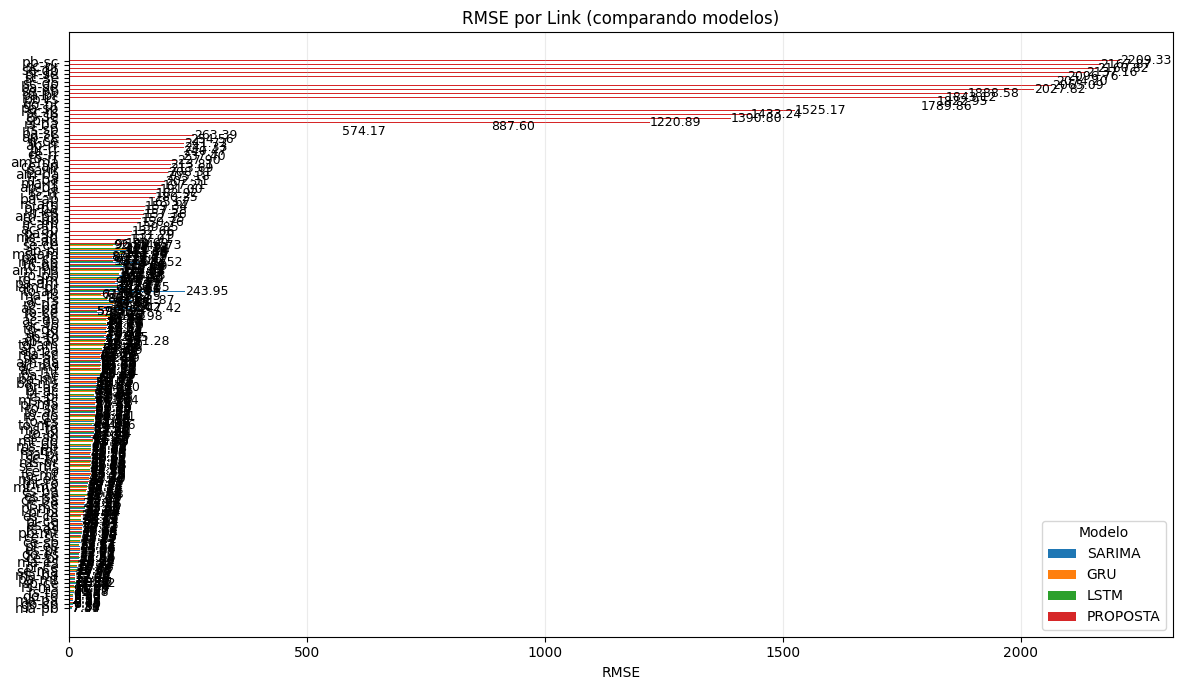

In [12]:
# ============================================
# Cell 5 — Plot 1: RMSE
# ============================================
plot_grouped_horizontal_bars(
    wide_rmse,
    metric="RMSE",
    title="RMSE por Link (comparando modelos)",
    sort_by="PROPOSTA",   # troque para "LSTM"/"GRU"/"SARIMA" se quiser
    top_n=None,           # ex: 25 para limitar
    annotate=True
)


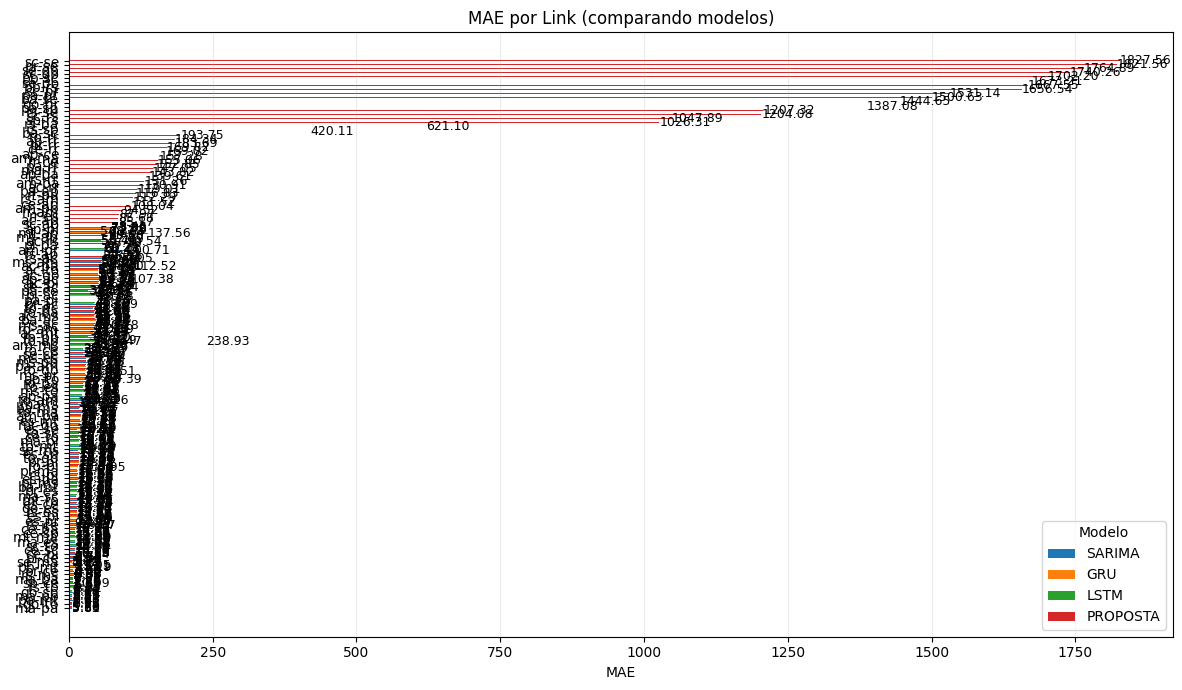

In [13]:
# ============================================
# Cell 6 — Plot 2: MAE
# ============================================
plot_grouped_horizontal_bars(
    wide_mae,
    metric="MAE",
    title="MAE por Link (comparando modelos)",
    sort_by="PROPOSTA",
    top_n=None,
    annotate=True
)


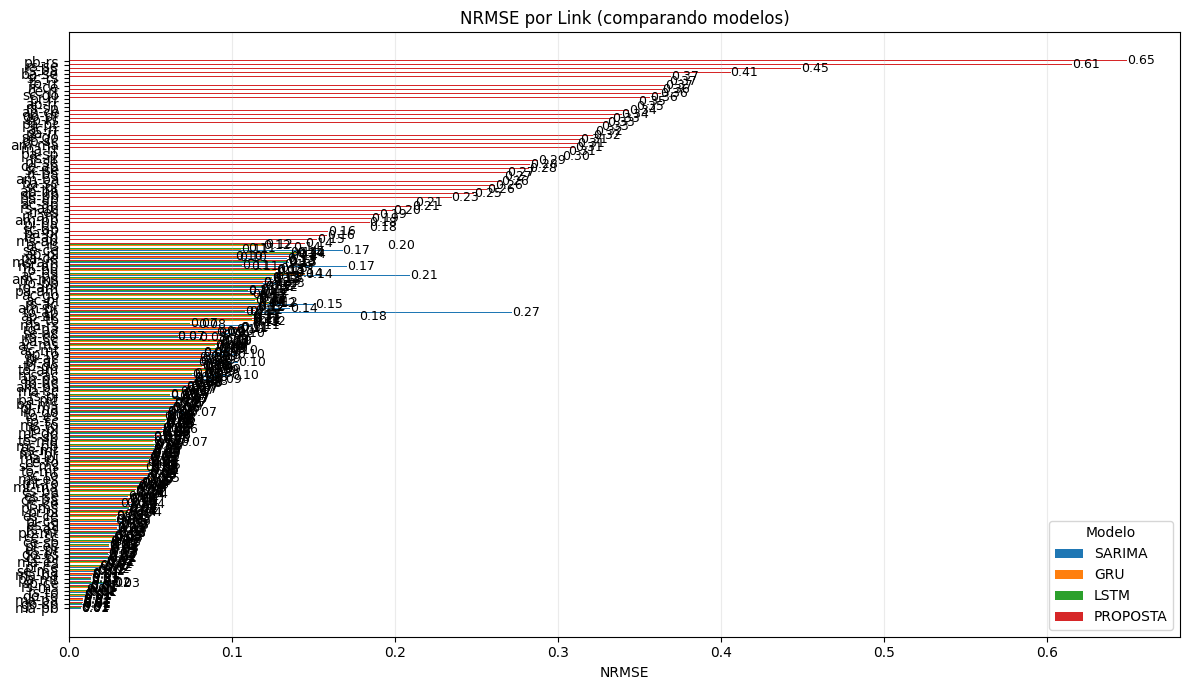

In [14]:
# ============================================
# Cell 7 — Plot 3: NRMSE
# ============================================
plot_grouped_horizontal_bars(
    wide_nrmse,
    metric="NRMSE",
    title="NRMSE por Link (comparando modelos)",
    sort_by="PROPOSTA",
    top_n=None,
    annotate=True
)


In [15]:
# ============================================
# Cell 8 — Helper: tabela estilo artigo
# ============================================
def build_article_table(df_long: pd.DataFrame, metric: str) -> pd.DataFrame:
    """
    Retorna tabela:
      index = link
      columns = modelos
      values = métrica (RMSE / MAE / NRMSE)
    """
    table = (
        df_long
        .pivot_table(
            index="link",
            columns="model",
            values=metric,
            aggfunc="mean"
        )
        .sort_index()
    )

    # garante ordem fixa das colunas
    table = table[[c for c in MODEL_FILES.keys() if c in table.columns]]
    return table

table_rmse  = build_article_table(df_long, "RMSE")
table_mae   = build_article_table(df_long, "MAE")
table_nrmse = build_article_table(df_long, "NRMSE")

table_rmse.head()


model,SARIMA,GRU,LSTM,PROPOSTA
link,,,,
ac-ap,NaN,NaN,NaN,139.845225
ac-go,81.166659,81.587711,78.817369,81.565448
ac-ms,65.600668,64.999659,66.801322,67.596975
ac-mt,71.812333,66.541167,66.321027,67.332421
ac-pa,147.422761,102.018436,97.841592,89.889439


In [17]:
# ============================================
# Cell 9 — RMSE table (sem style)
# ============================================
print("RMSE por Link e Modelo")
display(table_rmse.round(2))


RMSE por Link e Modelo


model,SARIMA,GRU,LSTM,PROPOSTA
link,,,,
ac-ap,NaN,NaN,NaN,139.85
ac-go,81.17,81.59,78.82,81.57
ac-ms,65.60,65.00,66.80,67.60
ac-mt,71.81,66.54,66.32,67.33
ac-pa,147.42,102.02,97.84,89.89
...,...,...,...,...
to-go,79.04,77.52,77.57,79.57
to-ma,64.96,49.06,52.06,54.36
to-mt,45.16,45.75,45.50,45.71


In [18]:
# ============================================
# Cell 10 — MAE table (sem style)
# ============================================
print("MAE por Link e Modelo")
display(table_mae.round(2))


MAE por Link e Modelo


model,SARIMA,GRU,LSTM,PROPOSTA
link,,,,
ac-ap,NaN,NaN,NaN,85.68
ac-go,53.67,50.40,50.44,54.92
ac-ms,46.75,43.76,43.98,45.57
ac-mt,44.77,42.33,42.82,43.64
ac-pa,112.52,68.60,64.91,56.43
...,...,...,...,...
to-go,17.26,18.52,18.46,18.46
to-ma,24.67,19.73,20.76,21.81
to-mt,21.29,19.58,19.63,18.95


In [19]:
# ============================================
# Cell 11 — NRMSE table (sem style)
# ============================================
print("NRMSE por Link e Modelo")
display(table_nrmse.round(3))


NRMSE por Link e Modelo


model,SARIMA,GRU,LSTM,PROPOSTA
link,,,,
ac-ap,NaN,NaN,NaN,0.212
ac-go,0.116,0.117,0.113,0.117
ac-ms,0.090,0.090,0.092,0.093
ac-mt,0.099,0.092,0.091,0.093
ac-pa,0.209,0.145,0.139,0.128
...,...,...,...,...
to-go,0.083,0.081,0.081,0.084
to-ma,0.068,0.052,0.055,0.057
to-mt,0.050,0.050,0.050,0.050


In [20]:
# table_nrmse.to_latex("nrmse_table.tex", float_format="%.3f")

In [21]:
# ============================================
# Cell 12 — Comparações par-a-par
# ============================================
def compare_models(table: pd.DataFrame, metric: str) -> pd.DataFrame:
    rows = []

    for link, row in table.iterrows():
        values = row.dropna()
        best_model = values.idxmin()
        best_value = values.min()

        for model, val in values.items():
            rows.append({
                "link": link,
                "metric": metric,
                "model": model,
                "value": val,
                "best_model": best_model,
                "delta_to_best": val - best_value
            })

    return pd.DataFrame(rows)

cmp_rmse  = compare_models(table_rmse, "RMSE")
cmp_mae   = compare_models(table_mae, "MAE")
cmp_nrmse = compare_models(table_nrmse, "NRMSE")

cmp_nrmse.head(10)


,link,metric,model,value,best_model,delta_to_best
0,ac-ap,NRMSE,PROPOSTA,0.212221,PROPOSTA,0.000000
1,ac-go,NRMSE,SARIMA,0.116012,LSTM,0.003358
2,ac-go,NRMSE,GRU,0.116614,LSTM,0.003960
3,ac-go,NRMSE,LSTM,0.112654,LSTM,0.000000
4,ac-go,NRMSE,PROPOSTA,0.116589,LSTM,0.003935
5,ac-ms,NRMSE,SARIMA,0.090373,GRU,0.000828
6,ac-ms,NRMSE,GRU,0.089545,GRU,0.000000
7,ac-ms,NRMSE,LSTM,0.092027,GRU,0.002482
8,ac-ms,NRMSE,PROPOSTA,0.093059,GRU,0.003514
9,ac-mt,NRMSE,SARIMA,0.099040,LSTM,0.007573


In [22]:
# ============================================
# Cell 13 — Análise da Proposta
# ============================================
def analyze_proposal(table: pd.DataFrame, metric: str) -> dict:
    df = table.dropna(subset=["PROPOSTA"])
    total_links = len(df)

    best_per_link = df.idxmin(axis=1)
    proposal_wins = (best_per_link == "PROPOSTA")

    n_wins = proposal_wins.sum()
    win_rate = n_wins / total_links * 100

    # diferença para o melhor concorrente
    diffs = []
    for link, row in df.iterrows():
        prop = row["PROPOSTA"]
        others = row.drop("PROPOSTA")
        best_other = others.min()

        diffs.append(prop - best_other)

    diffs = pd.Series(diffs, index=df.index)

    return {
        "metric": metric,
        "total_links": total_links,
        "proposal_wins": int(n_wins),
        "win_rate_%": win_rate,
        "avg_gain_when_wins": diffs[diffs < 0].abs().mean(),
        "avg_loss_when_loses": diffs[diffs > 0].mean(),
        "median_diff": diffs.median()
    }

analysis = pd.DataFrame([
    analyze_proposal(table_rmse,  "RMSE"),
    analyze_proposal(table_mae,   "MAE"),
    analyze_proposal(table_nrmse, "NRMSE"),
])

analysis


,metric,total_links,proposal_wins,win_rate_%,avg_gain_when_wins,avg_loss_when_loses,median_diff
0,RMSE,132,55,41.666667,2.242912,4.042855,1.436902
1,MAE,132,60,45.454545,2.351236,2.893406,1.310761
2,NRMSE,132,55,41.666667,0.002839,0.004724,0.001670


In [23]:
# ============================================
# Cell 14 — Texto interpretável
# ============================================
for _, row in analysis.iterrows():
    print(f"""
Métrica: {row['metric']}
----------------------------------------
Total de links analisados: {row['total_links']}
Vitórias da proposta: {row['proposal_wins']} ({row['win_rate_%']:.1f}%)

Ganho médio quando vence: {row['avg_gain_when_wins']:.4f}
Perda média quando perde: {row['avg_loss_when_loses']:.4f}
Diferença mediana (proposta - melhor baseline): {row['median_diff']:.4f}
""")



Métrica: RMSE
----------------------------------------
Total de links analisados: 132
Vitórias da proposta: 55 (41.7%)

Ganho médio quando vence: 2.2429
Perda média quando perde: 4.0429
Diferença mediana (proposta - melhor baseline): 1.4369


Métrica: MAE
----------------------------------------
Total de links analisados: 132
Vitórias da proposta: 60 (45.5%)

Ganho médio quando vence: 2.3512
Perda média quando perde: 2.8934
Diferença mediana (proposta - melhor baseline): 1.3108


Métrica: NRMSE
----------------------------------------
Total de links analisados: 132
Vitórias da proposta: 55 (41.7%)

Ganho médio quando vence: 0.0028
Perda média quando perde: 0.0047
Diferença mediana (proposta - melhor baseline): 0.0017



In [24]:
# ==========================================================
# Cell 15 — Filtrar links onde PROPOSTA ganhou (sem repetir estados)
# ==========================================================
import re
from collections import Counter

def states_from_link(link: str):
    """
    Espera link tipo 'ac-rs' (case-insensitive).
    Retorna tuple ('ac','rs') em minúsculo.
    """
    parts = re.split(r"[-–—]", link.strip().lower())
    if len(parts) != 2:
        return None
    a, b = parts[0].strip(), parts[1].strip()
    if not a or not b:
        return None
    return a, b

def proposal_winner_links(table: pd.DataFrame) -> pd.DataFrame:
    """
    Retorna subset (table) somente dos links onde PROPOSTA é a melhor (menor valor).
    Remove links sem PROPOSTA ou com parse inválido.
    """
    if "PROPOSTA" not in table.columns:
        raise ValueError("A tabela não tem a coluna 'PROPOSTA'.")

    df = table.dropna(subset=["PROPOSTA"]).copy()
    # garante que temos ao menos 1 baseline pra comparar
    other_cols = [c for c in df.columns if c != "PROPOSTA"]
    df = df.dropna(subset=other_cols, how="all")

    best_model = df.idxmin(axis=1)
    df = df[best_model == "PROPOSTA"]
    return df

def select_non_repeating_states(links, prefer_order=None):
    """
    Seleciona um subconjunto de links (iterando em ordem) tal que nenhum estado se repita.
    Ex: se seleciona 'ac-rs', não pode selecionar nenhum link com 'ac' ou 'rs' novamente.

    prefer_order: lista de links (na ordem que você quer priorizar). Se None, usa a ordem recebida.
    """
    selected = []
    used_states = set()

    iterable = prefer_order if prefer_order is not None else links

    for link in iterable:
        st = states_from_link(link)
        if st is None:
            continue
        a, b = st
        if a in used_states or b in used_states:
            continue
        selected.append(link)
        used_states.update([a, b])

    return selected, used_states

def build_filtered_wide(table: pd.DataFrame, selected_links: list) -> pd.DataFrame:
    """
    Constrói um wide DataFrame com coluna 'link' + colunas de modelos
    (no mesmo formato do wide_* das células anteriores), mas filtrado.
    """
    dfp = table.loc[selected_links].copy()
    dfp = dfp.reset_index().rename(columns={"index": "link"})
    # garante ordem das colunas
    cols = ["link"] + [m for m in MODEL_FILES.keys() if m in dfp.columns]
    return dfp[cols]

# Critério para "proposta ganhou":
# Vou usar NRMSE como critério principal (normalizado). Se preferir RMSE/MAE, troque aqui.
wins_table = proposal_winner_links(table_nrmse)

# Ordenação para priorizar links onde a proposta ganha "mais" (maior margem vs melhor baseline)
def order_by_margin(table_wins: pd.DataFrame) -> list:
    margins = {}
    for link, row in table_wins.iterrows():
        prop = row["PROPOSTA"]
        best_other = row.drop("PROPOSTA").min()
        margins[link] = (best_other - prop)  # quanto maior, mais a proposta foi melhor
    return [k for k, _ in sorted(margins.items(), key=lambda x: x[1], reverse=True)]

ordered_links = order_by_margin(wins_table)

selected_links, used_states = select_non_repeating_states(list(wins_table.index), prefer_order=ordered_links)

print(f"Links onde PROPOSTA ganhou (NRMSE) = {len(wins_table)}")
print(f"Selecionados sem repetir estados   = {len(selected_links)}")
print("Selecionados:", selected_links)
print("Estados usados:", sorted(list(used_states)))


Links onde PROPOSTA ganhou (NRMSE) = 11
Selecionados sem repetir estados   = 6
Selecionados: ['ac-pa', 'sp-ce', 'ap-pi', 'to-am', 'pb-mt', 'ms-es']
Estados usados: ['ac', 'am', 'ap', 'ce', 'es', 'ms', 'mt', 'pa', 'pb', 'pi', 'sp', 'to']


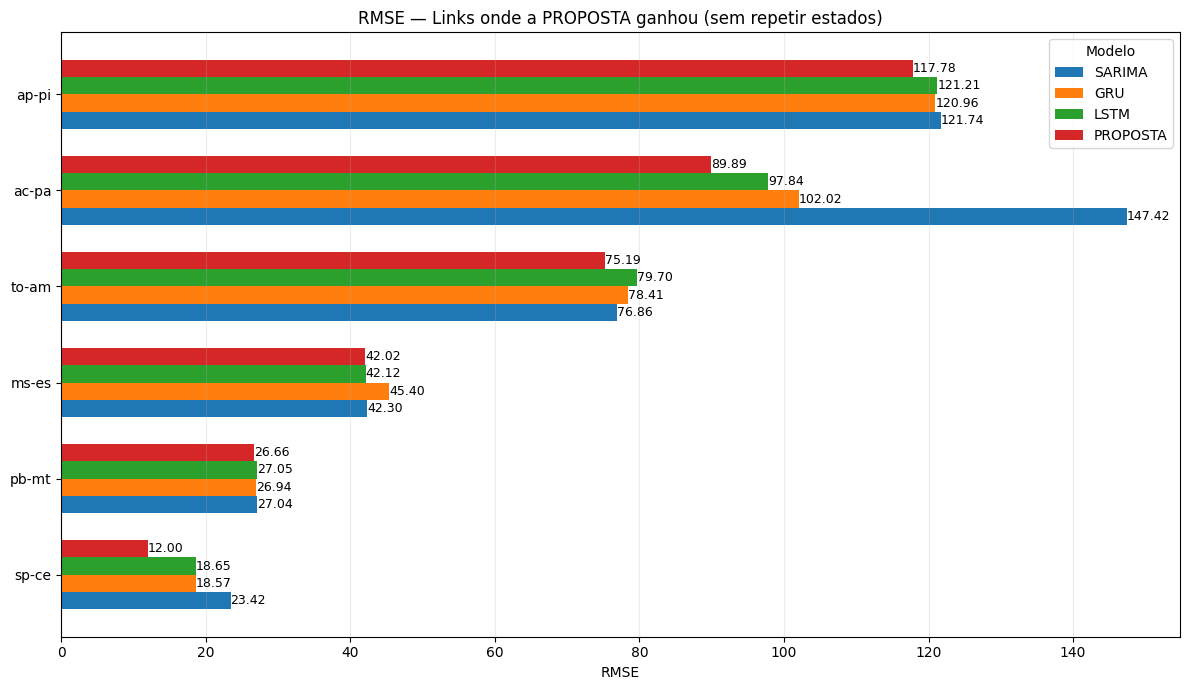

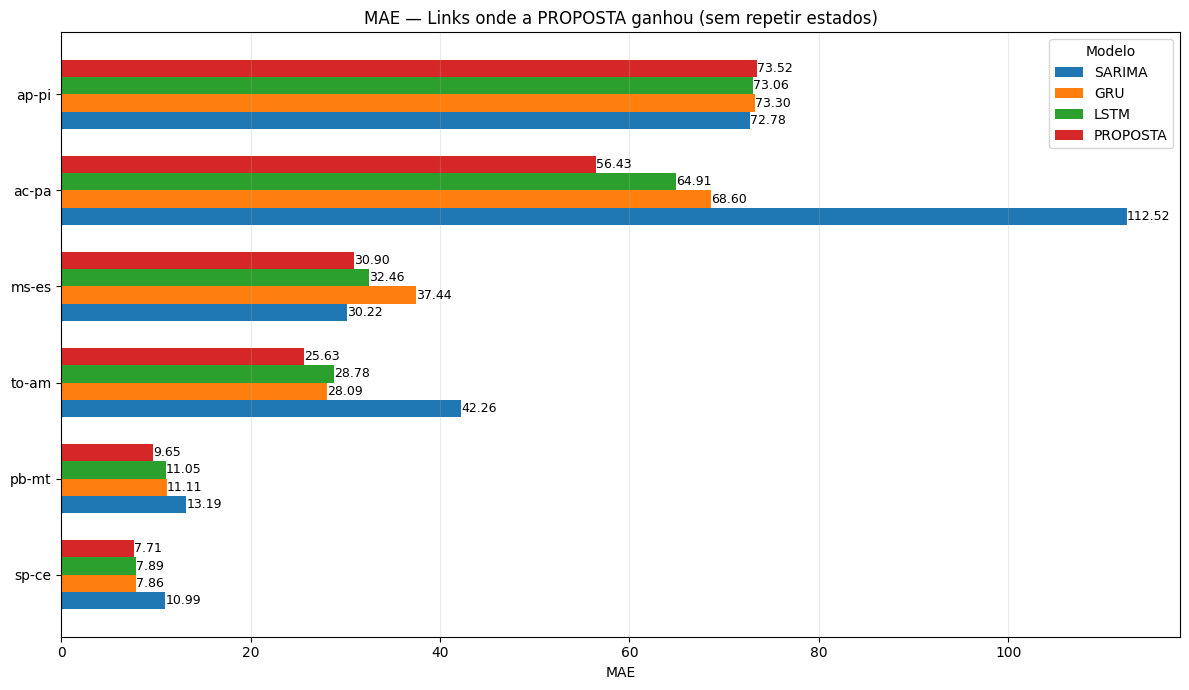

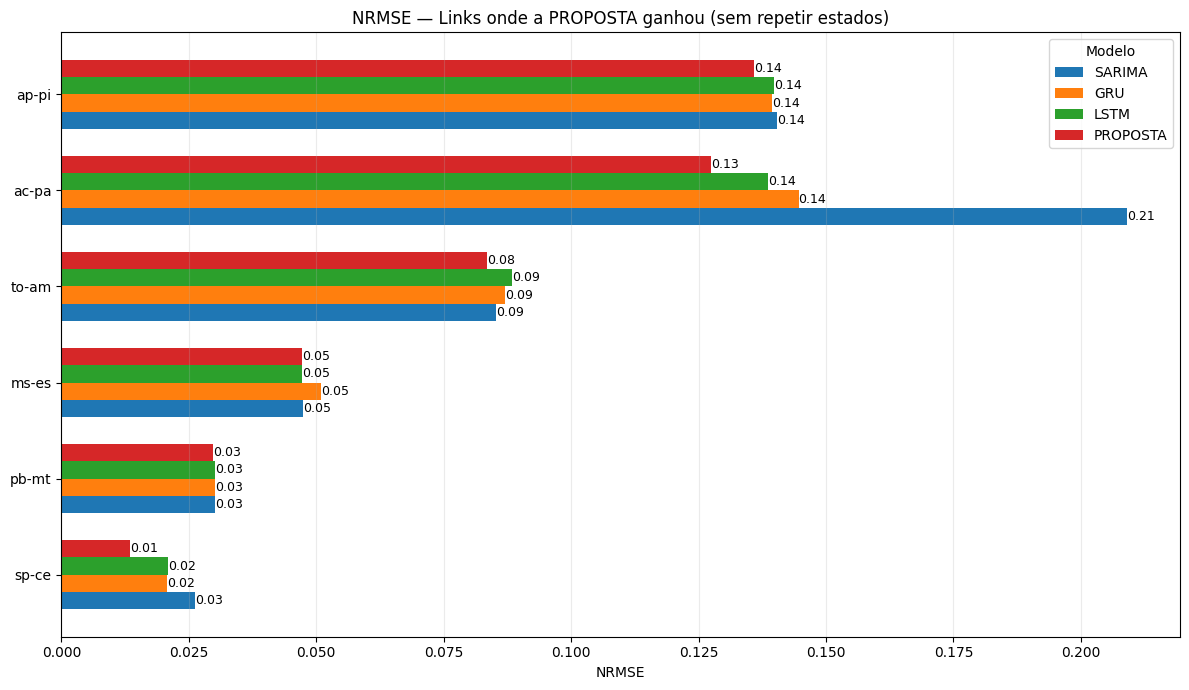

In [25]:
# ==========================================================
# Cell 16 — Construir wides filtrados (RMSE/MAE/NRMSE) e plotar
# ==========================================================
wide_rmse_f  = build_filtered_wide(table_rmse,  selected_links)
wide_mae_f   = build_filtered_wide(table_mae,   selected_links)
wide_nrmse_f = build_filtered_wide(table_nrmse, selected_links)

# Se quiser ordenar no gráfico pelo valor da PROPOSTA (ou por outra coluna), dá pra passar sort_by.
plot_grouped_horizontal_bars(
    wide_rmse_f,
    metric="RMSE",
    title="RMSE — Links onde a PROPOSTA ganhou (sem repetir estados)",
    sort_by="PROPOSTA",
    top_n=None,
    annotate=True
)

plot_grouped_horizontal_bars(
    wide_mae_f,
    metric="MAE",
    title="MAE — Links onde a PROPOSTA ganhou (sem repetir estados)",
    sort_by="PROPOSTA",
    top_n=None,
    annotate=True
)

plot_grouped_horizontal_bars(
    wide_nrmse_f,
    metric="NRMSE",
    title="NRMSE — Links onde a PROPOSTA ganhou (sem repetir estados)",
    sort_by="PROPOSTA",
    top_n=None,
    annotate=True
)


In [26]:
# ==========================================================
# Cell 17 — (Opcional) Ver tabela dos links selecionados
# ==========================================================
print("Tabela NRMSE (somente selecionados):")
display(table_nrmse.loc[selected_links].round(4))

print("\nTabela MAE (somente selecionados):")
display(table_mae.loc[selected_links].round(2))

print("\nTabela RMSE (somente selecionados):")
display(table_rmse.loc[selected_links].round(2))


Tabela NRMSE (somente selecionados):


model,SARIMA,GRU,LSTM,PROPOSTA
link,,,,
ac-pa,0.2090,0.1446,0.1387,0.1275
sp-ce,0.0262,0.0208,0.0209,0.0134
ap-pi,0.1404,0.1395,0.1398,0.1358
to-am,0.0853,0.0870,0.0885,0.0835
pb-mt,0.0302,0.0301,0.0302,0.0298
ms-es,0.0475,0.0510,0.0473,0.0472



Tabela MAE (somente selecionados):


model,SARIMA,GRU,LSTM,PROPOSTA
link,,,,
ac-pa,112.52,68.60,64.91,56.43
sp-ce,10.99,7.86,7.89,7.71
ap-pi,72.78,73.30,73.06,73.52
to-am,42.26,28.09,28.78,25.63
pb-mt,13.19,11.11,11.05,9.65
ms-es,30.22,37.44,32.46,30.90



Tabela RMSE (somente selecionados):


model,SARIMA,GRU,LSTM,PROPOSTA
link,,,,
ac-pa,147.42,102.02,97.84,89.89
sp-ce,23.42,18.57,18.65,12.00
ap-pi,121.74,120.96,121.21,117.78
to-am,76.86,78.41,79.70,75.19
pb-mt,27.04,26.94,27.05,26.66
ms-es,42.30,45.40,42.12,42.02
